# Escalator walkthrough

Escalator is a Strands agent where **Strands Decider 2B** decides, for each request, whether Amazon Nova Micro or Claude Haiku 4.5 on Amazon Bedrock should answer, or whether to ask the user for more detail. It also checks Nova Micro's answers before they are sent.

This notebook works from the saved benchmark results in `bench/reported/`, so it runs without AWS credentials or the decider. The last two sections call the live decider and Bedrock; they are switched off unless you set `RUN_LIVE = True`.

Code: https://github.com/Swayam-Ch/escalator · Video: https://youtu.be/PtXiIiXiwM4

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "bench")]

from escalator.patterns import AdequacyGate, GatePolicy, TierRouter
from sweep import replay

RUN_LIVE = False   # True calls the local decider and Amazon Bedrock (costs a few cents)


def load(name):
    path = ROOT / "bench" / "reported" / f"{name}-results.jsonl"
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]


runs = {"v1": load("v1-haiku"), "v2": load("v2-haiku"), "v2, held-out": load("holdout-haiku")}
{name: len(rows) for name, rows in runs.items()}

{'v1': 36, 'v2': 36, 'v2, held-out': 24}

## 1. The two decisions

Every request gets a **route** decision (a decider `choice`: small, large or clarify) before any LLM runs. If the small model answers, a **gate** decision (three yes/no questions and one rubric score, in one decider call) checks the draft before it is sent. The decider returns probabilities; the policy below is plain Python.

In [2]:
router, policy = TierRouter(decider=None), GatePolicy()
display(Markdown(f'''
| Knob | Value | Meaning |
| --- | ---: | --- |
| `TierRouter.large_at` | {router.large_at} | P(large) at or above this goes straight to the large model |
| `TierRouter.sure` | {router.sure} | confidence needed to ask the user to clarify |
| `GatePolicy.min_answers` | {policy.min_answers} | P(draft fully answers) needed to ship it |
| `GatePolicy.max_hedging` | {policy.max_hedging} | P(draft hedges) above which it escalates |
| `GatePolicy.max_high_stakes` | {policy.max_high_stakes} | P(high-stakes request) above which it escalates |
| `GatePolicy.min_quality` | {policy.min_quality} | expected rubric level (0 to 3) needed to ship |
'''))


| Knob | Value | Meaning |
| --- | ---: | --- |
| `TierRouter.large_at` | 0.82 | P(large) at or above this goes straight to the large model |
| `TierRouter.sure` | 0.9 | confidence needed to ask the user to clarify |
| `GatePolicy.min_answers` | 0.9 | P(draft fully answers) needed to ship it |
| `GatePolicy.max_hedging` | 0.5 | P(draft hedges) above which it escalates |
| `GatePolicy.max_high_stakes` | 0.5 | P(high-stakes request) above which it escalates |
| `GatePolicy.min_quality` | 2.0 | expected rubric level (0 to 3) needed to ship |


## 2. Results

Cost is measured from Bedrock token counts, against sending every question to Claude Haiku. Haiku also judges whether each answer Nova Micro shipped is as good as its own.

In [3]:
def summary(rows):
    base = sum(r["baseline_cost"] for r in rows)
    esc = sum(r["escalator_cost"] for r in rows)
    answered = [r for r in rows if r["path"] != "clarify"]
    worse = sum(1 for r in rows if r.get("judge_pass") is False)
    easy = [r for r in rows if r["kind"] == "easy" and r["path"] == "direct-small"]
    easy_saving = 1 - sum(r["escalator_cost"] for r in easy) / sum(r["baseline_cost"] for r in easy)
    return [len(rows), f"{esc / base - 1:+.0%}", f"{worse} of {len(answered)}", f"{-easy_saving:+.0%}"]


labels = ["Questions", "Cost vs. always-Haiku", "Answers worse than baseline", "Cost on easy questions answered by Nova Micro"]
table = {name: summary(rows) for name, rows in runs.items()}
lines = ["| | " + " | ".join(table) + " |", "| --- |" + " ---: |" * len(table)]
lines += [f"| {label} | " + " | ".join(str(col[i]) for col in table.values()) + " |" for i, label in enumerate(labels)]
display(Markdown("\n".join(lines)))

| | v1 | v2 | v2, held-out |
| --- | ---: | ---: | ---: |
| Questions | 36 | 36 | 24 |
| Cost vs. always-Haiku | -68% | -20% | -32% |
| Answers worse than baseline | 4 of 33 | 0 of 33 | 3 of 23 |
| Cost on easy questions answered by Nova Micro | -99% | -99% | -99% |

Where each question went in v2. `direct-small`: Nova Micro answered and the gate accepted it. `escalated`: the gate rejected Nova Micro's draft. `direct-large`: the router sent it straight to Haiku. `clarify`: the agent asked the user a question.

In [4]:
for name in ("v2", "v2, held-out"):
    counts = Counter((r["kind"], r["path"]) for r in runs[name])
    kinds = sorted({k for k, _ in counts}, key=["easy", "hard", "ambiguous", "high_stakes"].index)
    paths = ["direct-small", "escalated", "direct-large", "clarify"]
    lines = [f"**{name}**", "", "| kind | " + " | ".join(paths) + " |", "| --- |" + " ---: |" * len(paths)]
    lines += [f"| {k} | " + " | ".join(str(counts[(k, p)]) for p in paths) + " |" for k in kinds]
    display(Markdown("\n".join(lines)))

**v2**

| kind | direct-small | escalated | direct-large | clarify |
| --- | ---: | ---: | ---: | ---: |
| easy | 12 | 2 | 0 | 0 |
| hard | 3 | 1 | 10 | 0 |
| ambiguous | 0 | 1 | 0 | 3 |
| high_stakes | 0 | 2 | 2 | 0 |

**v2, held-out**

| kind | direct-small | escalated | direct-large | clarify |
| --- | ---: | ---: | ---: | ---: |
| easy | 9 | 1 | 0 | 0 |
| hard | 2 | 0 | 6 | 0 |
| ambiguous | 0 | 2 | 0 | 1 |
| high_stakes | 1 | 0 | 2 | 0 |

## 3. Why v1 failed and v2 routes on P(large)

v1 only skipped the cheap draft when the router picked `large` with confidence of at least 0.9, which never happened. The gate then let through bad drafts on code and maths, because it scored good and bad drafts alike. The router's P(large) had already separated the two groups:

In [5]:
shipped = [r for r in runs["v1"] if r["path"] == "direct-small"]
lines = ["| question | kind | P(large) | gate: answers | gate: quality | judge |", "| --- | --- | ---: | ---: | ---: | --- |"]
for r in sorted(shipped, key=lambda r: r["route"]["p_large"]):
    g = r.get("gate") or {}
    verdict = "PASS" if r["judge_pass"] else "**FAIL**"
    lines.append(f"| `{r['id']}` | {r['kind']} | {r['route']['p_large']:.2f} | {g.get('answers', float('nan')):.2f} | {g.get('quality', float('nan')):.2f} | {verdict} |")
display(Markdown("\n".join(lines)))

| question | kind | P(large) | gate: answers | gate: quality | judge |
| --- | --- | ---: | ---: | ---: | --- |
| `easy-10` | easy | 0.16 | 0.90 | 2.18 | PASS |
| `easy-06` | easy | 0.17 | 0.94 | 2.35 | PASS |
| `easy-09` | easy | 0.21 | 0.94 | 2.29 | PASS |
| `easy-08` | easy | 0.22 | 0.95 | 2.27 | PASS |
| `easy-04` | easy | 0.22 | 0.95 | 2.31 | PASS |
| `easy-02` | easy | 0.22 | 0.94 | 2.30 | PASS |
| `easy-11` | easy | 0.23 | 0.93 | 2.29 | PASS |
| `easy-01` | easy | 0.24 | 0.95 | 2.34 | PASS |
| `easy-12` | easy | 0.25 | 0.95 | 2.34 | PASS |
| `easy-03` | easy | 0.28 | 0.93 | 2.30 | PASS |
| `easy-07` | easy | 0.44 | 0.95 | 2.20 | PASS |
| `easy-05` | easy | 0.47 | 0.94 | 2.32 | PASS |
| `high_stakes-02` | high_stakes | 0.76 | 0.90 | 2.23 | PASS |
| `hard-03` | hard | 0.77 | 0.92 | 2.21 | PASS |
| `hard-09` | hard | 0.79 | 0.95 | 2.30 | PASS |
| `hard-02` | hard | 0.80 | 0.95 | 2.28 | PASS |
| `hard-11` | hard | 0.82 | 0.93 | 2.25 | PASS |
| `hard-08` | hard | 0.83 | 0.95 | 2.27 | **FAIL** |
| `hard-12` | hard | 0.86 | 0.95 | 2.29 | **FAIL** |
| `hard-07` | hard | 0.86 | 0.95 | 2.05 | **FAIL** |
| `hard-06` | hard | 0.87 | 0.91 | 2.10 | **FAIL** |
| `hard-04` | hard | 0.90 | 0.95 | 2.32 | PASS |

Every failure has P(large) above 0.82, while the gate's "answers" and "quality" scores look the same for passes and failures. `bench/sweep.py` replays the saved v1 run at every threshold, with no API calls:

In [6]:
lines = ["| P(large) threshold | Saving vs. always-Haiku | Answers worse than baseline |", "| ---: | ---: | ---: |"]
points, previous = [], None
for step in range(50, 100):
    result = replay(runs["v1"], step / 100)
    key = (result["shipped_small"], len(result["worse"]))
    points.append((result["saving"], len(result["worse"]), step / 100))
    if key != previous:
        lines.append(f"| {step / 100:.2f} | {result['saving']:.0%} | {len(result['worse'])} |")
        previous = key
display(Markdown("\n".join(lines)))

| P(large) threshold | Saving vs. always-Haiku | Answers worse than baseline |
| ---: | ---: | ---: |
| 0.50 | 13% | 0 |
| 0.76 | 17% | 0 |
| 0.77 | 20% | 0 |
| 0.79 | 23% | 0 |
| 0.81 | 30% | 0 |
| 0.83 | 40% | 1 |
| 0.86 | 43% | 2 |
| 0.87 | 46% | 3 |
| 0.88 | 64% | 4 |
| 0.90 | 68% | 4 |

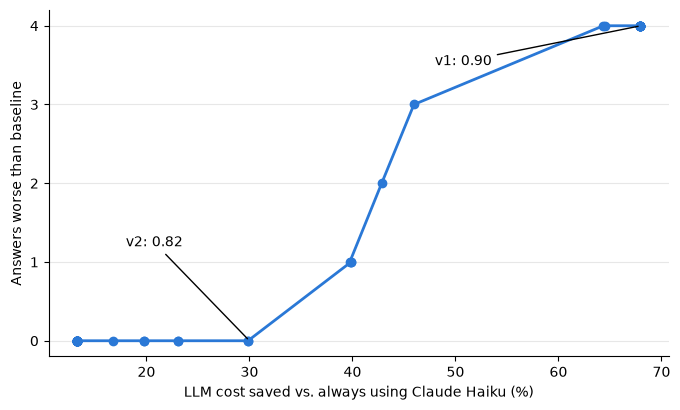

In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("pip install matplotlib to draw the chart")
else:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    xs, ys = [p[0] * 100 for p in points], [p[1] for p in points]
    ax.plot(xs, ys, marker="o", color="#2a78d6", linewidth=2)
    ax.annotate("v2: 0.82", (30, 0), xytext=(18, 1.2), arrowprops=dict(arrowstyle="-"))
    ax.annotate("v1: 0.90", (68, 4), xytext=(48, 3.5), arrowprops=dict(arrowstyle="-"))
    ax.set_xlabel("LLM cost saved vs. always using Claude Haiku (%)")
    ax.set_ylabel("Answers worse than baseline")
    ax.set_yticks(range(5))
    ax.grid(axis="y", alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.show()

## 4. Held-out check

0.82 was chosen on the same 36 questions v2 was tested on, so I also ran 24 new questions. The saving held up (32%), but some answers were worse than Haiku's. One of them is a strict grade: checked by hand, Nova Micro's rewrite was fine.

In [8]:
worse = [r for r in runs["v2, held-out"] if r.get("judge_pass") is False]
for r in worse:
    display(Markdown(f"**`{r['id']}`** (P(large) {r['route']['p_large']:.2f}): {r['prompt']}"))

rewrite = next((r for r in worse if r["id"] == "holdout-easy-08"), None)
if rewrite:
    display(Markdown(f"Nova Micro: {rewrite['escalator_answer']}\n\nHaiku: {rewrite['baseline_answer']}"))

**`holdout-easy-08`** (P(large) 0.13): Make this sentence shorter: 'At this point in time we are not able to proceed with the request.'

**`holdout-hard-01`** (P(large) 0.77): Write a Python function that checks whether a string of brackets like '([]{})' is balanced, and explain its time complexity.

**`holdout-high_stakes-03`** (P(large) 0.78): Can I deduct my home office on my taxes if I'm a full-time employee working remotely in the US?

Nova Micro: We can't proceed with the request now.

Haiku: "We cannot proceed with the request."

Or even shorter: "We cannot proceed."

## 5. The pattern on its own (live decider, optional)

`examples/minimal_cascade.py` runs the router and gate with plain Python functions in place of the LLMs. It needs only `strands-decider serve StrandsAgents/strands-decider-2B-qwen3.5-v1-2610 --port 8099`, no AWS account.

In [9]:
if RUN_LIVE:
    sys.path.insert(0, str(ROOT / "examples"))
    from escalator.decider import Decider
    from minimal_cascade import answer

    decider = Decider()
    for prompt in ["What is the capital of France?", "Can you fix it?"]:
        print(">", prompt)
        print("  answer:", answer(prompt, TierRouter(decider), AdequacyGate(decider)))
else:
    print("Set RUN_LIVE = True and start the decider to run this cell.")

Set RUN_LIVE = True and start the decider to run this cell.


## 6. The full agent on Amazon Bedrock (optional)

Needs the decider and AWS credentials with access to Nova Micro and Claude Haiku 4.5 in us-east-1.

In [10]:
if RUN_LIVE:
    from escalator.agent import Escalator
    from escalator.cli import render
    from escalator.decider import Decider

    decider = Decider()
    escalator = Escalator(TierRouter(decider), AdequacyGate(decider),
                          large_model="us.anthropic.claude-haiku-4-5-20251001-v1:0")
    print(render(escalator("What is the capital of Australia?")))
else:
    print("Set RUN_LIVE = True, start the decider and configure AWS credentials to run this cell.")

Set RUN_LIVE = True, start the decider and configure AWS credentials to run this cell.
